<a href="https://colab.research.google.com/github/Shxrp08/Project_SG_I-Smile_Group6_2026/blob/main/Project_SG_Group_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#ML Classification Model

### Library yg Hrs Dipanggil:

In [1]:
# Manipulasi Data dan Visual

import pandas as pd                                                              #Baca file CSV, ngolah isi data tabel, cari missing value
import numpy as np                                                               #Operasi matrix n array
import matplotlib.pyplot as plt                                                  #bikin tampilan gambar bewarna
import seaborn as sns                                                            #grafik warna-warni (penyempurna matplotlib)

#Pre-processing dan pemisahan data

from sklearn.model_selection import (
    train_test_split,                                                            # rasio train dan test; text_size=0.XX untuk skala 100-XX : XX
    cross_val_score                                                              # bagi data latih: cv=X, model dilatih X kali dr semua data latih yg dibagi X
)
from sklearn.preprocessing import (
    StandardScaler,                                                              # Feature scaling: standarisasi
#   MinMaxScaler,                                                                # Feature scaling: normalisasi
    OneHotEncoder,                                                               # text kategori nominal (gada tingkatan) jadi kolom biner 0/1
    OrdinalEncoder                                                               # kategori tingkatan jadi 0,1,2,3,...
)
from sklearn.compose import ColumnTransformer                                    #gabung teknik olah data berbeda (scaling, encoding), dlm satu alur
from sklearn.pipeline import Pipeline                                            #bungkus ColumnTransformer dan model ML jadi 1 paket biar gada data leakage

#Algoritma model klasifikasi

from sklearn.neighbors import KNeighborsClassifier                               #KNN
from sklearn.ensemble import RandomForestClassifier                              #Random Forest

#metrik evaluasi klasifikasi

from sklearn.metrics import (
    accuracy_score,                                                              # Accuracy
    precision_score,                                                             # Precision
    recall_score,                                                                # Recall
    confusion_matrix,                                                            # hitung tabel rekap tebakan benar vs salah (true/false positif, t/f negatif)
    ConfusionMatrixDisplay                                                       #ubah matrix jadi tabel bewarna
)

                                                    
### Memasukkan dataset yang mau digunakan (sebagai Data Path)

In [4]:
#DATA_PATH
DATA_PATH = "/content/ai_student_impact_dataset (1)-selected-columns.csv"        #Path dari dataset yang akan digunakan


df = pd.read_csv(DATA_PATH)                  #  df = data frame, pd = pandas     # Membaca data
print("Ukuran data (baris, kolom):", df.shape)                                   # Print teks, df.shape menunjukkan berapa banyak baris dan kolom pada csv
df.head(15)        #default = 5                                                    # Menampilkan berapa banyak indeks data yang akan ditampilkan pada kolom

Ukuran data (baris, kolom): (50000, 10)


,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35
3,100004,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23
4,100005,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55
5,100006,STEM,Junior,3.449,6.50,Debugging/Troubleshooting,Beginner,1,False,14.19
6,100007,STEM,Freshman,3.622,31.41,Summarizing_Reading,Advanced,5,True,13.11
7,100008,Arts,Junior,2.746,5.33,Copywriting/Drafting,Intermediate,3,False,18.45
8,100009,Business,Sophomore,3.420,2.00,Debugging/Troubleshooting,Beginner,2,True,2.87
9,100010,Business,Sophomore,3.046,19.99,Debugging/Troubleshooting,Intermediate,2,True,12.49



### Menampilkan tipe data dan jumlah nilai non-null (nilai tidak kosong)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Student_ID                50000 non-null  int64  
 1   Major_Category            50000 non-null  object 
 2   Year_of_Study             50000 non-null  object 
 3   Pre_Semester_GPA          50000 non-null  float64
 4   Weekly_GenAI_Hours        50000 non-null  float64
 5   Primary_Use_Case          50000 non-null  object 
 6   Prompt_Engineering_Skill  50000 non-null  object 
 7   Tool_Diversity            50000 non-null  int64  
 8   Paid_Subscription         50000 non-null  bool   
 9   Traditional_Study_Hours   50000 non-null  float64
dtypes: bool(1), float64(3), int64(2), object(4)
memory usage: 3.5+ MB


####______________________________________
## EDA (Exploratory Data Analysis)
####______________________________________

###1. Analisis Satu Variabel (value_counts)

In [9]:
# Kita bisa memakai fungsi value_counts untuk menghitung jumlah baris data (frekuensi) untuk setiap kategori

# misal, kita ambil dua kategori: Major_Category dan Year_of_Study

display(df["Major_Category"].value_counts())
display(df["Year_of_Study"].value_counts())

# kalau gk pake fungsi display dan menulis kedua panggilan dengan

#df["Year_of_Study"].value_counts()
#df["Major_Category"].value_counts()

#ipynb cuma bakal jalanin perintah terbawah!

,count
Major_Category,
STEM,15059
Business,12538
Humanities,9994
Medical,6476
Arts,5933


,count
Year_of_Study,
Junior,11045
Freshman,11031
Senior,10634
Sophomore,9860
Graduate,7430


In [20]:
# value_counts bisa juga buat tipe data selain kategori. tapi untuk kasus yang mungkin memiliki sangat banyak variasi (kayak float yang detail),
# kita berikan parameter bins untuk memberi batas rentang!

df["Pre_Semester_GPA"].value_counts(bins=5).reset_index() #Untuk mengubah bentuk Series tersebut menjadi DataFrame menggunakan .reset_index(),series itu seperti struktur data satu kolom

,index,count
0,"(2.872, 3.435]",20525
1,"(3.435, 3.998]",15907
2,"(2.309, 2.872]",10602
3,"(1.746, 2.309]",2717
4,"(1.179, 1.746]",249


In [ ]:
#Versi persentase untuk value_counts

(df["Primary_Use_Case"].value_counts(normalize=True) * 100).round(2)

# Normalize=True digunakan untuk merubah nilai desimal ke persentase
# Round(X) digunkan untuk membulatkan X angka dibelakang koma

,proportion
Primary_Use_Case,
Debugging/Troubleshooting,24.59
Copywriting/Drafting,24.02
Ideation,21.44
Summarizing_Reading,17.27
Direct_Answer_Generation,12.68


###2. Visualisasi

####2a. Membuat Histogram

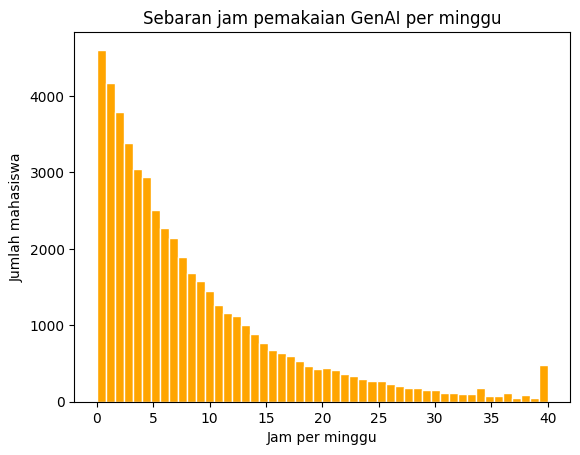

Banyak mahasiswa yang pake GenAI lebih dari 20 jam per minggu: 5006


In [ ]:
# Misal, kita membuat histogram terkait distribusi jam pemakaian GenAI per minggu dari informasi pada Weekly_GenAI_Hours yang ada di csv

# plt = pyplot

plt.hist(df["Weekly_GenAI_Hours"], bins=50, color="orange", edgecolor="white")      #plt.hist: membuat grafik histogram
plt.title("Sebaran jam pemakaian GenAI per minggu")                                 #plt.title: membuat judul dari histogram
plt.xlabel("Jam per minggu")                                                        #plt.xlabel: membuat nilai pada sumbu x
plt.ylabel("Jumlah mahasiswa")                                                      #plt.ylabel: membuat nilai pada sumbu y
plt.show()                                                                          #plt.show: menampilkan grafiknya

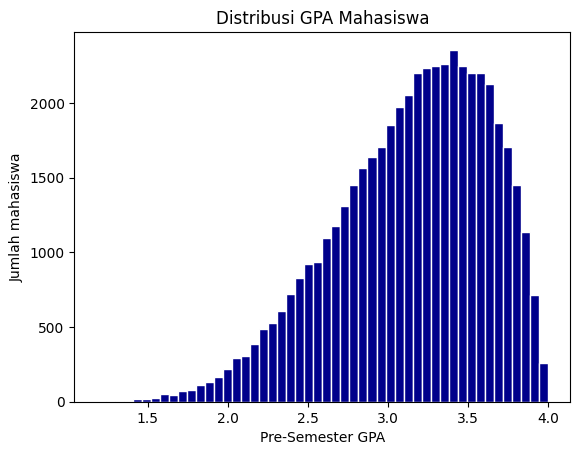

In [ ]:
# Misal, histogram terkait distribusi IPK(GPA) mahasiswa pre-semester yang ada pada tipe data Pre_Semester_GPA

plt.hist(df["Pre_Semester_GPA"], bins=50, color="darkblue", edgecolor="white")
plt.title("Distribusi GPA Mahasiswa")
plt.xlabel("Pre-Semester GPA")
plt.ylabel("Jumlah mahasiswa")
plt.show()

####2b. Conditional Counting: cek baris spesifik

In [35]:
#Misal, dari histogram sebelumnya, kita mencari berapa banyak mahasiswa dengan GPA X dengan parameter Pre_Semester_GPA

jumlah_mahasiswa_ipk = (df["Pre_Semester_GPA"] >= 3.5).sum()
print("Jumlah mahasiswa ber GPA lebih sama dengan dari 3.5:", jumlah_mahasiswa_ipk)

Jumlah mahasiswa ber GPA lebih sama dengan dari 3.5: 13346


In [36]:
#Bisa dicari dengan cara lain, seperti berikut:

print("Jumlah mahasiswa ber GPA lebih sama dengan dari 3.5::", (df["Pre_Semester_GPA"] >= 3.5).sum())


Jumlah mahasiswa ber GPA lebih sama dengan dari 3.5:: 13346


####2c. Sebaran/Distribusi

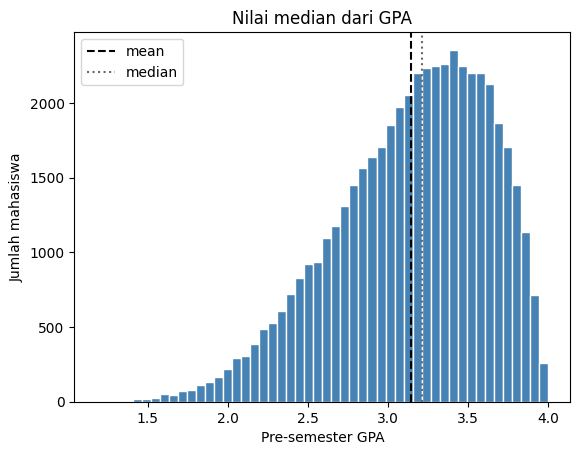

In [41]:
# Sebaran data

plt.hist(df["Pre_Semester_GPA"], bins=50, color="steelblue", edgecolor="white")
plt.axvline(df["Pre_Semester_GPA"].mean(), color="black", linestyle="--", label="mean") #untuk menunjukan mean (ditunjukkan dengan garis tebal putus putus)
plt.axvline(df["Pre_Semester_GPA"].median(), color="dimgray", linestyle=":", label="median") #untuk menunjukan garis tengah atau nilai median (ditunjukkan dengan garis tipis putus putus)
plt.title("Nilai median dari GPA")
plt.xlabel("Pre-semester GPA")
plt.ylabel("Jumlah mahasiswa")
plt.legend()
plt.show()

####2d. Hubungan GPA Mahasiswa dengan Sebaran jam pemakaian GenAI per minggu

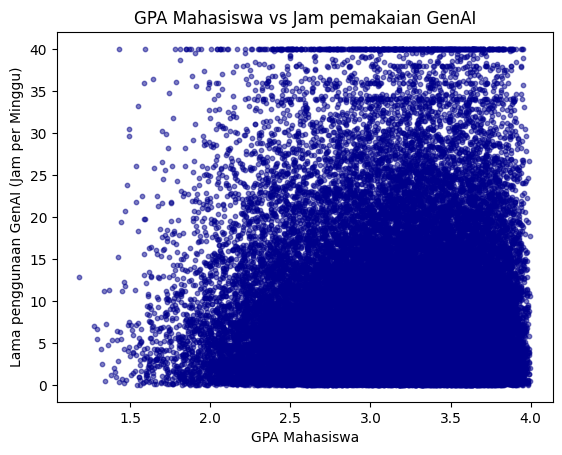

In [30]:
plt.scatter(df["Pre_Semester_GPA"], df["Weekly_GenAI_Hours"], alpha=0.5, s=10, color="darkblue")  # Menampoilkan nilai  dua data
plt.title("GPA Mahasiswa vs Jam pemakaian GenAI")
plt.xlabel("GPA Mahasiswa")
plt.ylabel("Lama penggunaan GenAI (Jam per Minggu)")
plt.show()

####2e. Boxplot

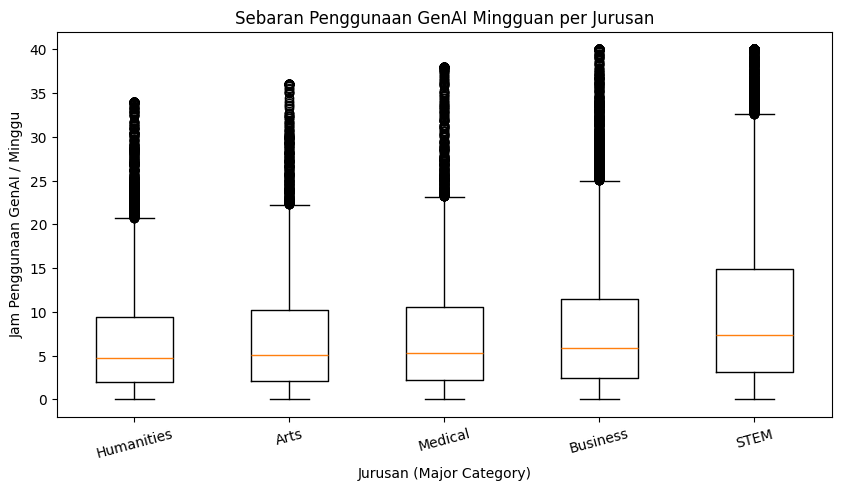

,Weekly_GenAI_Hours
Major_Category,
Humanities,4.72
Arts,5.07
Medical,5.24
Business,5.82
STEM,7.40


In [46]:
# Median jam GenAI per jurusan, diurutkan dari yang paling sedikit
median_per_jurusan = df.groupby("Major_Category")["Weekly_GenAI_Hours"].median().sort_values()
urutan = median_per_jurusan.index
jam_per_jurusan = [df.loc[df["Major_Category"] == k, "Weekly_GenAI_Hours"] for k in urutan]

plt.figure(figsize=(10, 5))
plt.boxplot(jam_per_jurusan)
plt.xticks(range(1, len(urutan) + 1), urutan, rotation=15)
plt.title("Sebaran Penggunaan GenAI Mingguan per Jurusan")
plt.xlabel("Jurusan (Major Category)")
plt.ylabel("Jam Penggunaan GenAI / Minggu")
plt.show()

median_per_jurusan

####2f. Heatmap

####_________________________
## Data Pre-Processing
####_________________________

### Template Tabel:
| A | B | C | D |
|-|-|-|-|
| lapu lapu | argus | zhuxin | kafka |
| | titan collector | pace | hsr |